# Awesome Clinic: Patient Visit Analysis (Dec 2025 – Jan 2026)

## Background
Awesome Clinic is a multi-department outpatient clinic with 35 doctors across
7 departments (Cardiology, Orthopedics, Neurology, General Physician, Oncology,
Psychiatry and Internal Medicine). Over December 2025 and January 2026 it recorded
4,207 patient visits.

## Problem statement
Clinic management has visit records but little visibility into how the clinic is
actually used. They don't know which departments and doctors carry the heaviest
workload, who their patients are, how long patients stay, or what drives the need
for follow-up appointments. Without this, staffing, scheduling and follow-up
planning are based on guesswork.

**Goal:** analyse the visit records to understand demand, patient profile and
follow-up needs, and give management clear, data-backed recommendations.

## Key questions
1. **Workload:** Which departments and doctors see the most patients? Is the load
   evenly shared?
2. **Patient profile:** What is the age and gender mix of patients, and how does it
   differ by department?
3. **Length of stay:** How long do patients stay, and which departments keep them
   longest?
4. **Follow-ups:** What share of visits need a follow-up, and is this linked to
   department, age or length of stay?
5. **Timing:** Which days of the week are busiest? How did the holiday period
   affect visits?
6. **Referrals:** Where do referred patients come from, and which departments
   do they go to?

## Data
- `Patients` sheet: one row per visit (patient ID, date of birth, gender, post code,
  referral source, in/out dates, doctor ID, follow-up flag)
- `Doctors` sheet: doctor name, doctor ID and department
- The two sheets are joined on `Doctor ID`.

## Scope and limitations
- Covers two months only (1 Dec 2025 – 31 Jan 2026), so seasonal conclusions are limited.
- No diagnosis, cost or outcome data, so the analysis describes usage, not quality of care.
- A blank "Referred by" is treated as a walk-in (not referred).

## Deliverables
- A cleaned, combined dataset
- Charts answering each key question
- A summary of findings and 3–5 recommendations for management

## Step 1: Load and clean the data

This step turns the two raw sheets into one clean table, `df`, with one row per visit. The rest of the analysis uses that table.

### 1.1 Load both sheets
We import pandas, point to the Excel file and read the `Patients` and `Doctors` sheets. The file path is set here as well, so this step still runs after a kernel restart.

In [12]:
import pandas as pd

f = "clinic_visits_2026.xlsx"

patients = pd.read_excel(f, sheet_name="Patients")
doctors = pd.read_excel(f, sheet_name="Doctors")

print("Patients:", patients.shape)
print("Doctors:", doctors.shape)
patients.head()

Patients: (4207, 9)
Doctors: (35, 3)


,Patient ID,DOB,Gender,Post Code,Referred by,In Date,Out Date,Doctor ID,Follow-up required?
0,PT0000006,1959-03-14,F,2682,NaN,2025-12-07,2025-12-07,DOC028,No
1,PT0000010,1980-04-06,M,629,NaN,2025-12-07,2025-12-07,DOC004,Yes
2,PT0000014,1983-01-21,M,1025,Hamilton,2025-12-31,2026-01-01,DOC002,Yes
3,PT0000018,1971-02-07,M,2012,NaN,2025-12-20,2025-12-21,DOC007,No
4,PT0000019,2005-11-01,M,930,Taupo,2026-01-16,2026-01-16,DOC023,No


### 1.2 Tidy the column names
Column names like `Follow-up required?` are awkward to type in code. We make them lowercase, swap spaces and hyphens for underscores, and drop the `?`. For example, `Follow-up required?` becomes `follow_up_required`.

In [13]:
def clean_cols(df):
    df.columns = (df.columns.str.strip().str.lower()
                  .str.replace("?", "", regex=False)
                  .str.replace(r"[\s-]+", "_", regex=True))
    return df

patients = clean_cols(patients)
doctors = clean_cols(doctors)

print(patients.columns.tolist())
print(doctors.columns.tolist())

['patient_id', 'dob', 'gender', 'post_code', 'referred_by', 'in_date', 'out_date', 'doctor_id', 'follow_up_required']
['doctor', 'doctor_id', 'department']


### 1.3 Tidy the doctor names
Doctor names have inconsistent capitals, such as `VALUE Arjun`, `ROWland Reagan` and `ShaHIDE Kapoor`. That looks messy in charts and reports. We remove stray spaces and put each name in title case (first letter of each word capital, the rest lower), so `VALUE Arjun` becomes `Value Arjun`.

In [14]:
before = doctors["doctor"].copy()
doctors["doctor"] = doctors["doctor"].str.strip().str.title()

# Show only the names that changed
changed = before != doctors["doctor"]
print(f"{changed.sum()} of {len(doctors)} names changed")
pd.DataFrame({"before": before[changed], "after": doctors["doctor"][changed]})

24 of 35 names changed


,before,after
5,ROWland Reagan,Rowland Reagan
9,Abraham LinColumn,Abraham Lincolumn
10,Harry S TRUEman,Harry S Trueman
11,John IF Kennedy,John If Kennedy
12,Wood ROW Wilson,Wood Row Wilson
14,Ulysses S. GrandTotal,Ulysses S. Grandtotal
15,Dwight D. EisenLower,Dwight D. Eisenlower
17,Amitabh FUNCTION,Amitabh Function
18,Shahrukh SCAN,Shahrukh Scan
19,Aishwarya ROW,Aishwarya Row


### 1.4 Fix the post codes
Excel saved post codes as numbers, so leading zeros were lost (`0629` became `629`). A post code is a label, not a quantity, so we store it as 4-digit text.

In [15]:
patients["post_code"] = patients["post_code"].astype(str).str.zfill(4)

patients["post_code"].head()

0    2682
1    0629
2    1025
3    2012
4    0930
Name: post_code, dtype: str

### 1.5 Fill in the blanks
- **Gender**: 14 visits have no gender recorded. We label them `"Unknown"` so they aren't silently dropped from counts.
- **Referred by**: 85% of visits have this blank. As set out in the scope, a blank means the patient walked in, so we label these `"Walk-in"`.

In [16]:
patients["gender"] = patients["gender"].fillna("Unknown")
patients["referred_by"] = patients["referred_by"].fillna("Walk-in")

print(patients["gender"].value_counts())
print()
print(patients["referred_by"].value_counts())

gender
M          2329
F          1847
O            17
Unknown      14
Name: count, dtype: int64

referred_by
Walk-in             3592
Hamilton              68
Masterton             63
Napier                61
Wellington            59
Taupo                 56
Gisborne              53
New Plymouth          53
Nelson                52
Tauranga              51
Palmerston North      50
Rotorua               49
Name: count, dtype: int64


### 1.6 Turn the follow-up flag into True/False
`Yes`/`No` text becomes `True`/`False`. That lets us work out follow-up rates directly: the average of a True/False column is the share that are True.

In [17]:
patients["follow_up_required"] = patients["follow_up_required"].map({"Yes": True, "No": False})

patients["follow_up_required"].value_counts()

follow_up_required
False    3131
True     1076
Name: count, dtype: int64

### 1.7 Join patients to doctors
We match each visit to its doctor on `doctor_id`, which adds the doctor's name and department. `validate="many_to_one"` makes pandas raise an error if a doctor ID appears more than once in the Doctors sheet, because that would duplicate visits.

In [18]:
df = patients.merge(doctors, on="doctor_id", how="left", validate="many_to_one")

print(df.shape)
df[["patient_id", "doctor_id", "doctor", "department"]].head()

(4207, 11)


,patient_id,doctor_id,doctor,department
0,PT0000006,DOC028,Value Arjun,Cardiology
1,PT0000010,DOC004,Donald Roundup,General Physician
2,PT0000014,DOC002,Large Bush,Orthopedics
3,PT0000018,DOC007,Jimmy Charter,Internal Medicine
4,PT0000019,DOC023,Pra Base,Neurology


### 1.8 Add the columns the analysis needs
- `age`: the patient's age in whole years on the day of the visit
- `length_of_stay`: days from in date to out date (0 = left the same day)
- `referred`: `True` if another town referred the patient, `False` for walk-ins

In [19]:
df["age"] = ((df["in_date"] - df["dob"]).dt.days / 365.25).astype(int)
df["length_of_stay"] = (df["out_date"] - df["in_date"]).dt.days
df["referred"] = df["referred_by"] != "Walk-in"

df[["age", "length_of_stay", "referred"]].describe(include="all")

,age,length_of_stay,referred
count,4207.000000,4207.000000,4207
unique,NaN,NaN,2
top,NaN,NaN,False
freq,NaN,NaN,3592
mean,46.063941,0.378179,NaN
std,14.457488,0.597052,NaN
min,7.000000,0.000000,NaN
25%,36.000000,0.000000,NaN
50%,48.000000,0.000000,NaN
75%,58.000000,1.000000,NaN


### 1.9 Check the cleaned data
Before analysing, we confirm three things. If any of them fails, the cell stops with an error message:
- every visit ID appears only once
- every visit matched a doctor and department
- no visit has an out date before its in date

In [20]:
assert df["patient_id"].is_unique, "duplicate visit IDs"
assert df["department"].notna().all(), "some visits have an unknown doctor"
assert (df["length_of_stay"] >= 0).all(), "out date before in date"

print("All checks passed:", df.shape)
df.head()

All checks passed: (4207, 14)


,patient_id,dob,gender,post_code,referred_by,in_date,out_date,doctor_id,follow_up_required,doctor,department,age,length_of_stay,referred
0,PT0000006,1959-03-14,F,2682,Walk-in,2025-12-07,2025-12-07,DOC028,False,Value Arjun,Cardiology,66,0,False
1,PT0000010,1980-04-06,M,0629,Walk-in,2025-12-07,2025-12-07,DOC004,True,Donald Roundup,General Physician,45,0,False
2,PT0000014,1983-01-21,M,1025,Hamilton,2025-12-31,2026-01-01,DOC002,True,Large Bush,Orthopedics,42,1,True
3,PT0000018,1971-02-07,M,2012,Walk-in,2025-12-20,2025-12-21,DOC007,False,Jimmy Charter,Internal Medicine,54,1,False
4,PT0000019,2005-11-01,M,0930,Taupo,2026-01-16,2026-01-16,DOC023,False,Pra Base,Neurology,20,0,True


## Step 2: Question 1 – Workload
**Which departments and doctors see the most patients? Is the load evenly shared?**

We count visits by department, then by doctor, and then compare how evenly the work is spread.

> Note: the data only tells us *how many visits* each doctor had. We don't know their working hours or days, so a low count could mean a part-time doctor rather than spare capacity.

### 2.1 Set up the chart style
We use one plain style for every chart in this notebook: a single blue for the data, gray for reference lines, and no box around the plot.

In [21]:
import matplotlib.pyplot as plt

BLUE = "#2a78d6"   # data
GRAY = "#898781"   # reference lines, axis labels
INK = "#0b0b0b"    # titles

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e",
    "xtick.color": GRAY,
    "ytick.color": "#52514e",
    "axes.grid": False,
})

### 2.2 Visits by department
For each department we count the visits and doctors, then work out the average **visits per doctor** and the department's **share** of all visits. Visits per doctor is the fairer comparison, because departments have different numbers of doctors.

In [22]:
dept_load = (df.groupby("department")
               .agg(visits=("patient_id", "size"), doctors=("doctor_id", "nunique")))
dept_load["visits_per_doctor"] = (dept_load["visits"] / dept_load["doctors"]).round(1)
dept_load["share_%"] = (dept_load["visits"] / len(df) * 100).round(1)
dept_load = dept_load.sort_values("visits", ascending=False)

dept_load

,visits,doctors,visits_per_doctor,share_%
department,,,,
Neurology,784,5,156.8,18.6
General Physician,780,6,130.0,18.5
Psychiatry,640,5,128.0,15.2
Cardiology,605,6,100.8,14.4
Oncology,530,5,106.0,12.6
Orthopedics,508,5,101.6,12.1
Internal Medicine,360,3,120.0,8.6


### 2.3 Chart: visits by department

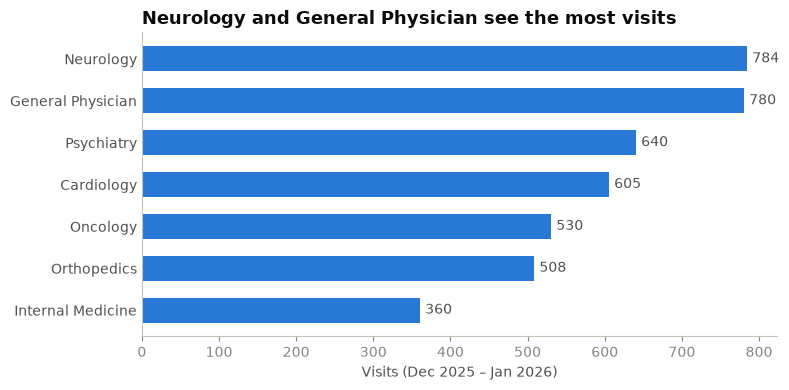

In [23]:
data = dept_load.sort_values("visits")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(data.index, data["visits"], color=BLUE, height=0.6)
ax.bar_label(bars, padding=4, color="#52514e")
ax.set_title("Neurology and General Physician see the most visits")
ax.set_xlabel("Visits (Dec 2025 – Jan 2026)")
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### 2.4 Visits per doctor
Next we count visits for each doctor. The five busiest and five quietest are shown below.

In [24]:
doctor_load = (df.groupby(["doctor", "department"])
                 .size()
                 .rename("visits")
                 .reset_index()
                 .sort_values("visits", ascending=False, ignore_index=True))

print("Busiest 5")
display(doctor_load.head(5))
print("Quietest 5")
display(doctor_load.tail(5))

Busiest 5


,doctor,department,visits
0,Vishwanatan Anand,General Physician,234
1,Dwight D. Eisenlower,Neurology,231
2,Donald Roundup,General Physician,222
3,Wood Row Wilson,Psychiatry,219
4,Pra Base,Neurology,208


Quietest 5


,doctor,department,visits
30,Rajini Coth,Cardiology,35
31,Viright Kohli,Cardiology,34
32,Mammo T,Orthopedics,28
33,Kapil Day,Neurology,23
34,Gerald Find,Cardiology,23


### 2.5 Chart: visits for every doctor
Each bar is one doctor, labelled with their department. The dashed line is the clinic average, so you can see at a glance who is above or below it.

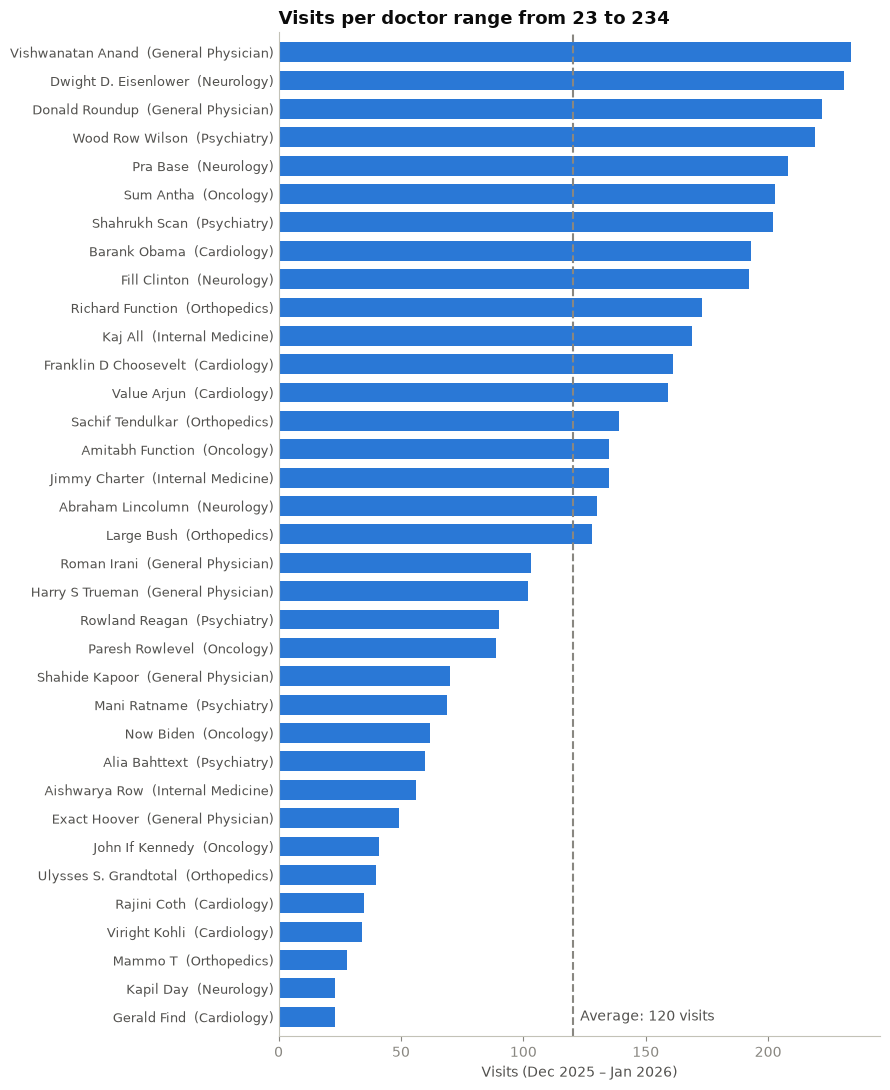

In [25]:
data = doctor_load.sort_values("visits")
labels = data["doctor"] + "  (" + data["department"] + ")"
avg = doctor_load["visits"].mean()

fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(labels, data["visits"], color=BLUE, height=0.7)
ax.axvline(avg, color=GRAY, linestyle="--", linewidth=1.5)
ax.text(avg + 3, 0, f"Average: {avg:.0f} visits", color="#52514e", va="center")
ax.set_title("Visits per doctor range from 23 to 234")
ax.set_xlabel("Visits (Dec 2025 – Jan 2026)")
ax.tick_params(axis="y", length=0, labelsize=9)
ax.margins(y=0.01)
plt.tight_layout()
plt.show()

### 2.6 Is the load evenly shared?
We summarise the spread in a few numbers:
- the average, lowest and highest visits per doctor
- how many times busier the busiest doctor is than the quietest
- how many doctors are well above (over 1.5× the average) or well below (under half the average) a typical load

In [26]:
v = doctor_load["visits"]
avg = v.mean()

summary = pd.Series({
    "Average visits per doctor": round(avg, 1),
    "Median visits per doctor": v.median(),
    "Lowest": v.min(),
    "Highest": v.max(),
    "Busiest ÷ quietest": round(v.max() / v.min(), 1),
    "Doctors over 1.5× average": (v > 1.5 * avg).sum(),
    "Doctors under half the average": (v < 0.5 * avg).sum(),
})
summary

Average visits per doctor         120.2
Median visits per doctor          128.0
Lowest                             23.0
Highest                           234.0
Busiest ÷ quietest                 10.2
Doctors over 1.5× average           9.0
Doctors under half the average     10.0
dtype: float64

### 2.7 Spread within each department
Uneven totals could just reflect department size. To check, we plot every doctor as a dot on their department's row. A wide spread within one row means doctors **in the same department** carry very different loads.

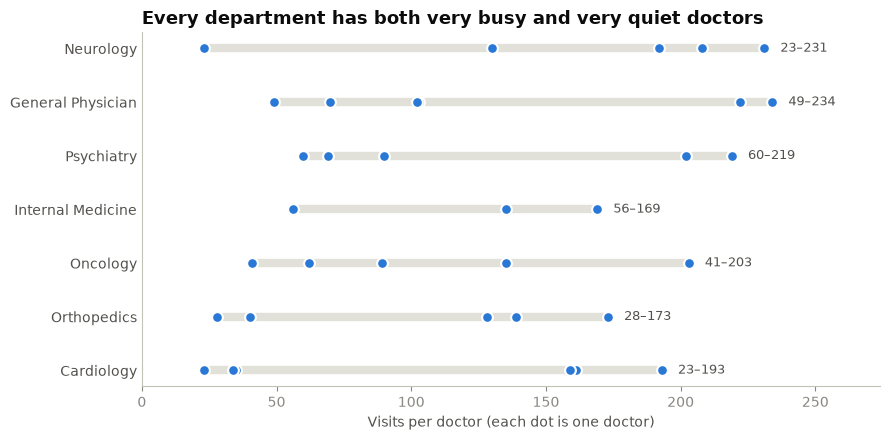

In [27]:
order = dept_load.sort_values("visits_per_doctor").index

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, dept in enumerate(order):
    vals = doctor_load.loc[doctor_load["department"] == dept, "visits"]
    ax.plot([vals.min(), vals.max()], [i, i], color="#e1e0d9", linewidth=6, solid_capstyle="round", zorder=1)
    ax.scatter(vals, [i] * len(vals), color=BLUE, s=60, edgecolor="white", linewidth=1.5, zorder=2)
    ax.text(vals.max() + 6, i, f"{vals.min()}–{vals.max()}", va="center", color="#52514e", fontsize=9)

ax.set_yticks(range(len(order)), order)
ax.set_title("Every department has both very busy and very quiet doctors")
ax.set_xlabel("Visits per doctor (each dot is one doctor)")
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, doctor_load["visits"].max() + 40)
plt.tight_layout()
plt.show()

### 2.8 Findings: workload
- **Busiest departments:** Neurology (784 visits, 18.6%) and General Physician (780, 18.5%) together handle over a third of all visits. Neurology has the heaviest load per doctor, at **157 visits each**.
- **Quietest department:** Internal Medicine has the fewest visits (360, 8.6%), but it also has only 3 doctors, so its load per doctor (120) is about average.
- **The load is not shared evenly.** Doctors average 120 visits, but the range runs from **23 to 234**, a 10× gap. Only about half of the doctors (16 of 35) are near the average: 9 see over 1.5× the average and 10 see under half of it.
  - Busiest: Vishwanatan Anand (General Physician, 234), Dwight D. Eisenlower (Neurology, 231), Donald Roundup (General Physician, 222)
  - Quietest: Kapil Day (Neurology, 23), Gerald Find (Cardiology, 23), Mammo T (Orthopedics, 28)
- **The imbalance is within departments, not just between them.** Every department has doctors far apart. In Neurology, one doctor saw 231 patients and another saw 23.

**What this suggests:** before hiring, management could check whether visits can be shared more evenly *within* each department, starting with Neurology and General Physician. It's worth confirming working hours first, since low counts may belong to part-time doctors.

## Step 3: Question 2 – Patient profile
**What is the age and gender mix of patients, and how does it differ by department?**

We look at the clinic as a whole first, then compare departments.

> Note: every patient ID appears only once, so each visit is a different patient. "Patients" and "visits" mean the same thing here.

### 3.1 Group patients by age
Single ages are hard to compare, so we put each patient into one of five age bands: **Under 18, 18–29, 30–44, 45–59, 60+**. The new `age_group` column is added to `df` for later steps.

In [28]:
age_bins = [0, 18, 30, 45, 60, 120]
age_labels = ["Under 18", "18–29", "30–44", "45–59", "60+"]
df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=age_labels, right=False)

age_mix = df["age_group"].value_counts(sort=False).to_frame("patients")
age_mix["share_%"] = (age_mix["patients"] / len(df) * 100).round(1)

print(df["age"].describe().round(1))
age_mix

count    4207.0
mean       46.1
std        14.5
min         7.0
25%        36.0
50%        48.0
75%        58.0
max        69.0
Name: age, dtype: float64


,patients,share_%
age_group,,
Under 18,175,4.2
18–29,475,11.3
30–44,1075,25.6
45–59,1596,37.9
60+,886,21.1


### 3.2 Chart: patients by age group

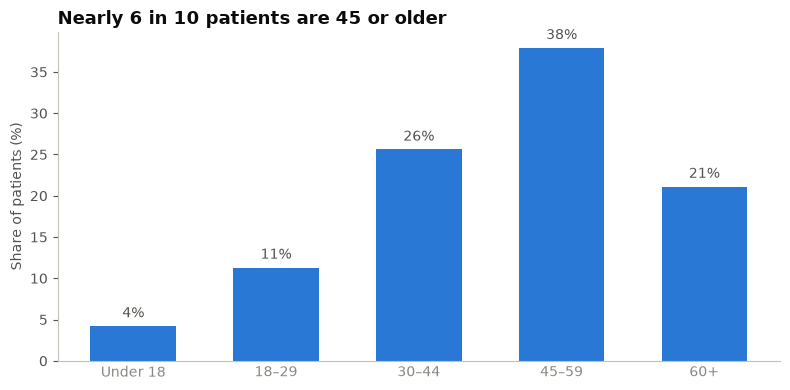

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(age_mix.index, age_mix["share_%"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in age_mix["share_%"]], padding=4, color="#52514e")
ax.set_title("Nearly 6 in 10 patients are 45 or older")
ax.set_ylabel("Share of patients (%)")
ax.tick_params(axis="x", length=0)
plt.tight_layout()
plt.show()

### 3.3 Gender mix
Patients recorded as `O` (other) or `Unknown` are kept in the table so the totals still add up to 100%.

In [30]:
gender_mix = df["gender"].value_counts().to_frame("patients")
gender_mix["share_%"] = (gender_mix["patients"] / len(df) * 100).round(1)
gender_mix

,patients,share_%
gender,,
M,2329,55.4
F,1847,43.9
O,17,0.4
Unknown,14,0.3


### 3.4 Chart: patients by gender

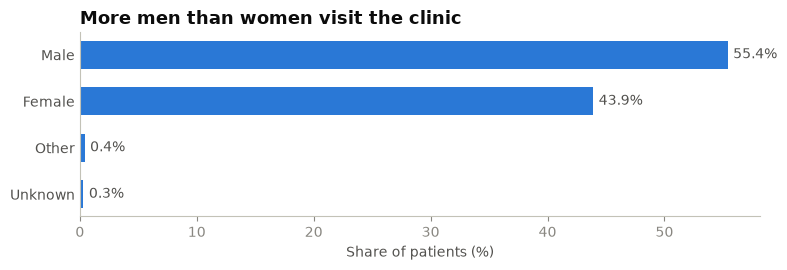

In [31]:
data = gender_mix.sort_values("share_%")
names = {"M": "Male", "F": "Female", "O": "Other", "Unknown": "Unknown"}

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(data.index.map(names), data["share_%"], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in data["share_%"]], padding=4, color="#52514e")
ax.set_title("More men than women visit the clinic")
ax.set_xlabel("Share of patients (%)")
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### 3.5 Age mix by department
Each row shows how one department's patients split across the age groups, and each row adds up to 100%. Darker cells mean a bigger share. If departments served different age groups, the dark cells would sit in different columns.

In [32]:
dept_age = (pd.crosstab(df["department"], df["age_group"], normalize="index") * 100).round(1)
dept_age["median_age"] = df.groupby("department")["age"].median()
dept_age = dept_age.sort_values("median_age")
dept_age

age_group,Under 18,18–29,30–44,45–59,60+,median_age
department,,,,,,
General Physician,3.6,11.7,28.1,37.3,19.4,47.0
Cardiology,3.8,11.7,25.6,38.8,20.0,48.0
Psychiatry,4.4,10.3,28.1,36.7,20.5,48.0
Orthopedics,3.9,13.2,23.4,37.8,21.7,48.0
Oncology,5.1,12.3,24.3,36.4,21.9,49.0
Neurology,4.7,10.5,24.0,39.7,21.2,50.0
Internal Medicine,3.3,9.2,23.6,38.6,25.3,52.0


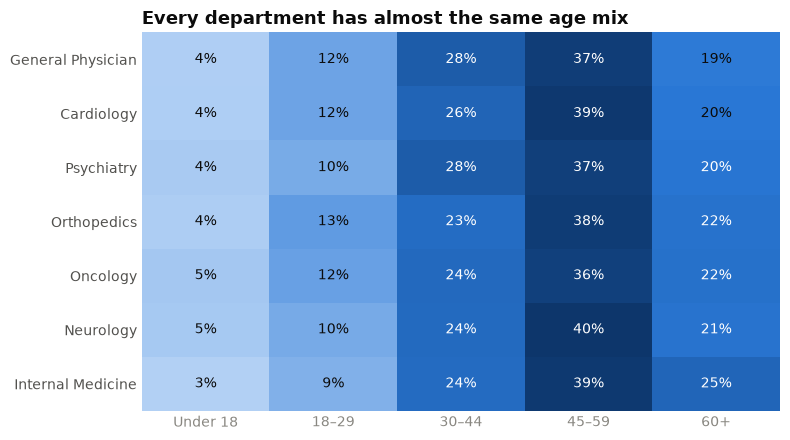

In [33]:
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])
grid = dept_age[age_labels]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.imshow(grid, cmap=blues, aspect="auto", vmin=0, vmax=grid.values.max())
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        val = grid.iat[i, j]
        ax.text(j, i, f"{val:.0f}%", ha="center", va="center",
                color="white" if val > 20 else INK, fontsize=10)

ax.set_xticks(range(len(age_labels)), age_labels)
ax.set_yticks(range(len(grid)), grid.index)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Every department has almost the same age mix")
plt.tight_layout()
plt.show()

### 3.6 Gender mix by department
We compare the **share of female patients** in each department against the clinic-wide figure (dashed line). Male patients make up nearly all of the rest, since Other and Unknown together are under 1%.

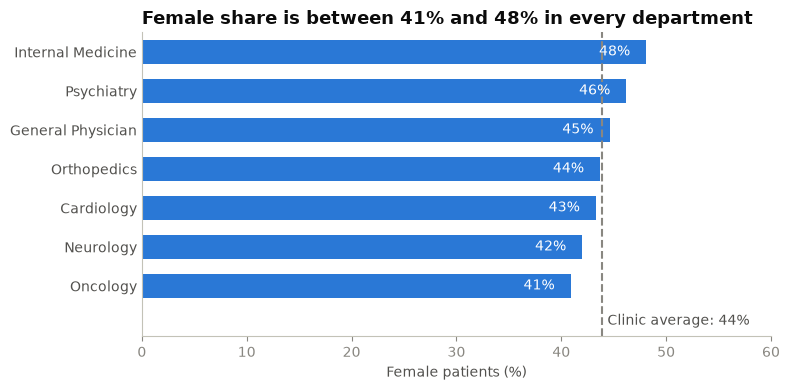

gender,F,M,O,Unknown
department,,,,
Oncology,40.9,58.3,0.4,0.4
Neurology,42.0,57.3,0.5,0.3
Cardiology,43.3,56.4,0.2,0.2
Orthopedics,43.7,55.5,0.0,0.8
General Physician,44.6,54.5,0.5,0.4
Psychiatry,46.2,52.8,0.8,0.2
Internal Medicine,48.1,51.4,0.3,0.3


In [34]:
dept_gender = (pd.crosstab(df["department"], df["gender"], normalize="index") * 100).round(1)
dept_gender = dept_gender.sort_values("F")
clinic_female = (df["gender"] == "F").mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(dept_gender.index, dept_gender["F"], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in dept_gender["F"]], padding=-34, color="white")
ax.axvline(clinic_female, color=GRAY, linestyle="--", linewidth=1.5)
ax.text(clinic_female + 0.5, -0.9, f"Clinic average: {clinic_female:.0f}%", color="#52514e", va="center")
ax.set_ylim(-1.3, len(dept_gender) - 0.5)
ax.set_xlim(0, 60)
ax.set_title("Female share is between 41% and 48% in every department")
ax.set_xlabel("Female patients (%)")
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

dept_gender

### 3.7 Findings: patient profile
- **Mostly middle-aged and older.** The median patient is 48. Patients aged **45–59 are the biggest group (38%)**, and 59% of patients are 45 or older. Children (under 18) are only 4%.
- **More men than women:** 55% male, 44% female, under 1% other or unknown.
- **Departments look almost identical.** Every department's age mix is within a few points of the clinic average, with median ages from 47 to 52. Internal Medicine is slightly older: 25% of its patients are 60+, against 21% clinic-wide. The female share only varies from 41% (Oncology) to 48% (Internal Medicine).
- **The data set is simulated,** which explains why the departments look alike: children appear in Cardiology, Oncology and Psychiatry at the same rate as everywhere else, which a real clinic wouldn't show. In practice, age and gender **don't explain** the workload differences in Step 2.

**What this suggests:** services and waiting areas should be planned around patients aged 45 and over, who make up the majority. Since every department sees the same mix, there's no need to plan a different patient mix for each department.

## Step 4: Question 3 – Length of stay
**How long do patients stay, and which departments keep them longest?**

Length of stay is the number of nights between the in date and the out date. 0 means the patient went home the same day.

### 4.1 How long do patients stay?
We count patients by number of nights. We also add a simpler `stay_type` column (**Same day**, **1 night**, **2+ nights**) for the department comparisons, because stays of 2 and 3 nights are too rare to compare separately.

In [36]:
df["stay_type"] = pd.cut(df["length_of_stay"], bins=[-1, 0, 1, 99],
                         labels=["Same day", "1 night", "2+ nights"])

nights = df["length_of_stay"].value_counts().sort_index().to_frame("patients")
nights["share_%"] = (nights["patients"] / len(df) * 100).round(1)

print(f"Average stay: {df['length_of_stay'].mean():.2f} nights")
nights

Average stay: 0.38 nights


,patients,share_%
length_of_stay,,
0,2861,68.0
1,1111,26.4
2,225,5.3
3,10,0.2


### 4.2 Chart: nights stayed

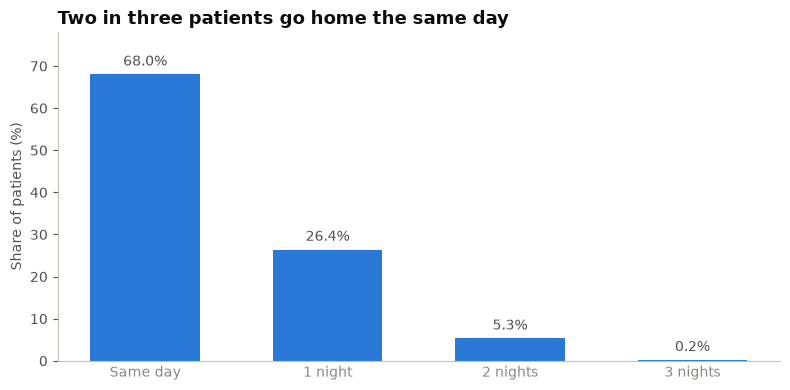

In [37]:
labels = ["Same day" if n == 0 else f"{n} night" + ("s" if n > 1 else "") for n in nights.index]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, nights["share_%"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in nights["share_%"]], padding=4, color="#52514e")
ax.set_title("Two in three patients go home the same day")
ax.set_ylabel("Share of patients (%)")
ax.set_ylim(0, 78)
ax.tick_params(axis="x", length=0)
plt.tight_layout()
plt.show()

### 4.3 Length of stay by department
For each department:
- **avg_nights**: average nights per patient
- **overnight_%**: share of patients who stayed at least one night
- **long_stay_%**: share who stayed 2 nights or more
- **bed_nights**: total nights across all patients. This shows where beds are used most, because it combines how many patients a department sees with how long they stay.

In [38]:
dept_stay = df.groupby("department").agg(
    patients=("patient_id", "size"),
    avg_nights=("length_of_stay", "mean"),
    overnight_pct=("length_of_stay", lambda s: (s > 0).mean() * 100),
    long_stay_pct=("length_of_stay", lambda s: (s >= 2).mean() * 100),
    bed_nights=("length_of_stay", "sum"),
).round(2)
dept_stay = dept_stay.rename(columns={"overnight_pct": "overnight_%", "long_stay_pct": "long_stay_%"})
dept_stay = dept_stay.sort_values("avg_nights", ascending=False)
dept_stay

,patients,avg_nights,overnight_%,long_stay_%,bed_nights
department,,,,,
Internal Medicine,360,0.41,32.78,7.78,148
Psychiatry,640,0.40,33.28,5.62,253
Cardiology,605,0.38,32.89,4.96,231
General Physician,780,0.38,32.44,5.90,300
Oncology,530,0.38,32.26,5.47,200
Neurology,784,0.36,30.87,5.48,286
Orthopedics,508,0.34,29.53,4.53,173


### 4.4 Chart: stay type by department
Each bar is one department split into same-day, 1-night and 2+-night patients, adding up to 100%. Darker blue means a longer stay. If one department kept patients much longer, its dark segments would be visibly wider.

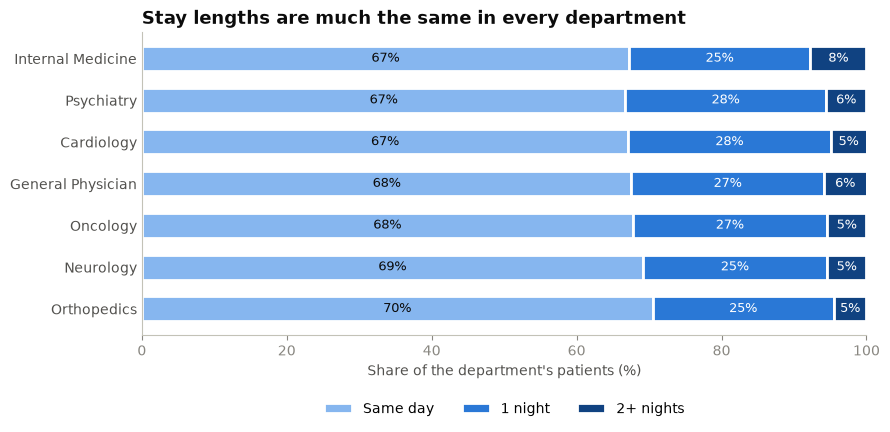

In [39]:
stay_mix = (pd.crosstab(df["department"], df["stay_type"], normalize="index") * 100)
stay_mix = stay_mix.loc[dept_stay.index[::-1]]          # longest average stay at the top
shades = ["#86b6ef", "#2a78d6", "#104281"]              # light → dark = short → long

fig, ax = plt.subplots(figsize=(9, 4.5))
left = pd.Series(0.0, index=stay_mix.index)
for col, shade in zip(stay_mix.columns, shades):
    bars = ax.barh(stay_mix.index, stay_mix[col], left=left, color=shade,
                   height=0.6, edgecolor="white", linewidth=2, label=col)
    ax.bar_label(bars, labels=[f"{v:.0f}%" for v in stay_mix[col]], label_type="center",
                 color=INK if shade == shades[0] else "white", fontsize=9)
    left += stay_mix[col]

ax.set_xlim(0, 100)
ax.set_title("Stay lengths are much the same in every department")
ax.set_xlabel("Share of the department's patients (%)")
ax.tick_params(axis="y", length=0)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout()
plt.show()

### 4.5 Chart: total bed-nights by department
This is where overnight capacity actually goes. Because stay lengths are similar everywhere, departments that see more patients use more beds.

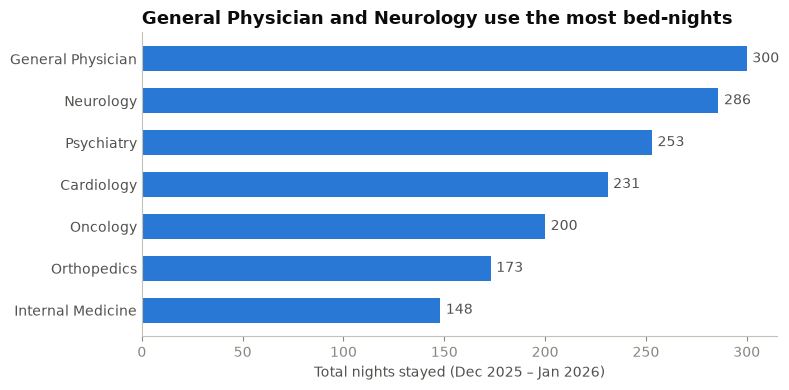

In [40]:
data = dept_stay.sort_values("bed_nights")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(data.index, data["bed_nights"], color=BLUE, height=0.6)
ax.bar_label(bars, padding=4, color="#52514e")
ax.set_title("General Physician and Neurology use the most bed-nights")
ax.set_xlabel("Total nights stayed (Dec 2025 – Jan 2026)")
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### 4.6 Does age change the length of stay?
A quick check: do older patients stay longer?

In [41]:
age_stay = df.groupby("age_group", observed=True).agg(
    avg_nights=("length_of_stay", "mean"),
    overnight_pct=("length_of_stay", lambda s: (s > 0).mean() * 100),
).round(2).rename(columns={"overnight_pct": "overnight_%"})
age_stay

,avg_nights,overnight_%
age_group,,
Under 18,0.35,31.43
18–29,0.36,31.16
30–44,0.38,31.44
45–59,0.38,32.08
60+,0.39,33.07


### 4.7 Findings: length of stay
- **Most visits are short.** **68%** of patients go home the same day and 26% stay one night. Only 5.5% stay 2 nights or more, and no one stays longer than 3. The average stay is 0.38 nights.
- **Departments differ very little.** Average stays range only from 0.34 nights (Orthopedics) to 0.41 (Internal Medicine), and about 30–33% of patients stay overnight in every department.
- **Internal Medicine has the most long stays:** 7.8% of its patients stay 2+ nights, against 5.5% clinic-wide. It's the only department that stands out, and with just 360 patients the difference is small.
- **Bed use follows patient volume.** General Physician (300 bed-nights) and Neurology (286) use the most beds simply because they see the most patients.
- **Age barely matters.** Patients aged 60+ stay overnight slightly more often (33%) than under-18s (31%).

**What this suggests:** overnight beds should be planned around **patient volume**, not department type. For about every three patients a department sees, expect one to stay overnight. General Physician and Neurology need the most beds. (As the data is simulated, the even pattern across departments is likely a feature of how it was generated.)

## Step 5: Question 4 – Follow-ups
**What share of visits need a follow-up, and is this linked to department, age or length of stay?**

We find the overall follow-up rate first, then compare groups. Small gaps between groups can happen by chance, so we also give each rate a **margin of error** to tell real differences from noise.

### 5.1 Overall follow-up rate

In [42]:
clinic_fu = df["follow_up_required"].mean() * 100

print(f"Visits needing a follow-up: {df['follow_up_required'].sum()} of {len(df)} ({clinic_fu:.1f}%)")

Visits needing a follow-up: 1076 of 4207 (25.6%)


### 5.2 Helper: follow-up rate by group, with a margin of error
This function works out the follow-up rate for each group, along with a **95% range** (`low_%` to `high_%`). The range is the band the true rate very likely falls in, and it's wider for small groups because fewer patients give a less certain estimate.

**How to read it:** if a group's range includes the clinic average, its rate isn't clearly different from the rest of the clinic.

In [43]:
def follow_up_by(column):
    t = df.groupby(column, observed=True)["follow_up_required"].agg(patients="size", follow_ups="sum")
    rate = t["follow_ups"] / t["patients"]
    margin = 1.96 * (rate * (1 - rate) / t["patients"]) ** 0.5
    t["rate_%"] = (rate * 100).round(1)
    t["low_%"] = ((rate - margin) * 100).round(1)
    t["high_%"] = ((rate + margin) * 100).round(1)
    return t

### 5.3 Helper: chart of follow-up rates
Every chart in this step uses the same layout: a **dot** for each group's rate, a **gray bar** for its 95% range, and a **dashed line** for the clinic average.

In [45]:
def plot_follow_up(t, title):
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(t) + 1.6))
    y = range(len(t))
    ax.hlines(y, t["low_%"], t["high_%"], color="#c3c2b7", linewidth=6, zorder=1)
    ax.scatter(t["rate_%"], y, color=BLUE, s=70, edgecolor="white", linewidth=1.5, zorder=2)
    for i, (rate, high) in enumerate(zip(t["rate_%"], t["high_%"])):
        ax.text(high + 0.6, i, f"{rate:.1f}%", va="center", color="#52514e", fontsize=9)
    ax.axvline(clinic_fu, color=GRAY, linestyle="--", linewidth=1.5)
    ax.text(clinic_fu + 0.3, -0.9, f"Clinic: {clinic_fu:.1f}%", color="#52514e", va="center", fontsize=9)
    ax.set_yticks(list(y), t.index.astype(str))
    ax.set_ylim(-1.3, len(t) - 0.5)
    ax.set_xlim(10, 40)
    ax.set_title(title)
    ax.set_xlabel("Follow-up rate (%), with 95% range")
    ax.tick_params(axis="y", length=0)
    plt.tight_layout()
    plt.show()

### 5.4 Follow-ups by department
`follow_ups` is the number of follow-up appointments each department will need to schedule. It matters for planning even when the *rate* is similar.

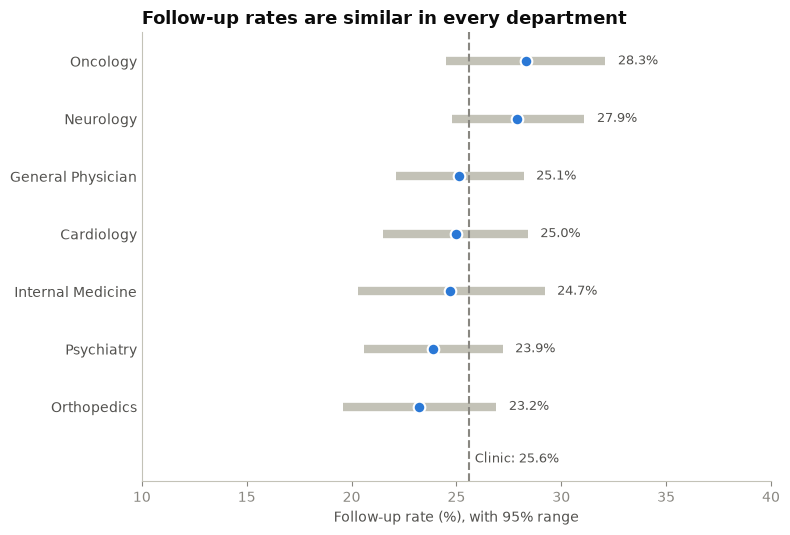

,patients,follow_ups,rate_%,low_%,high_%
department,,,,,
Orthopedics,508,118,23.2,19.6,26.9
Psychiatry,640,153,23.9,20.6,27.2
Internal Medicine,360,89,24.7,20.3,29.2
Cardiology,605,151,25.0,21.5,28.4
General Physician,780,196,25.1,22.1,28.2
Neurology,784,219,27.9,24.8,31.1
Oncology,530,150,28.3,24.5,32.1


In [46]:
fu_dept = follow_up_by("department").sort_values("rate_%")
plot_follow_up(fu_dept, "Follow-up rates are similar in every department")
fu_dept

### 5.5 Follow-ups by age group

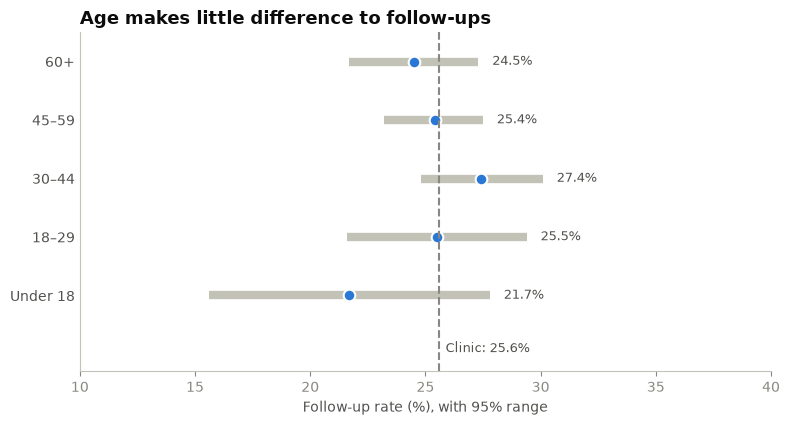

,patients,follow_ups,rate_%,low_%,high_%
age_group,,,,,
Under 18,175,38,21.7,15.6,27.8
18–29,475,121,25.5,21.6,29.4
30–44,1075,295,27.4,24.8,30.1
45–59,1596,405,25.4,23.2,27.5
60+,886,217,24.5,21.7,27.3


In [47]:
fu_age = follow_up_by("age_group")
plot_follow_up(fu_age, "Age makes little difference to follow-ups")
fu_age

### 5.6 Follow-ups by length of stay

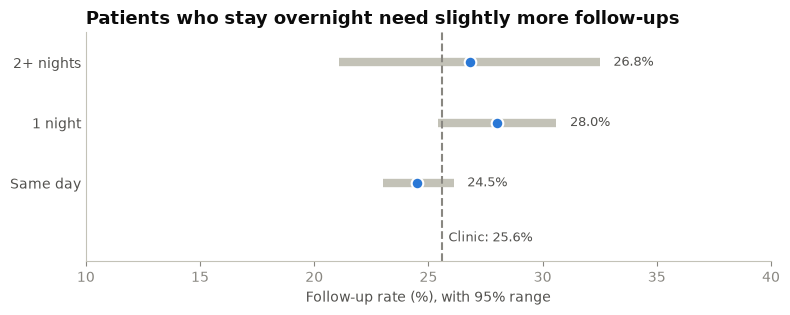

,patients,follow_ups,rate_%,low_%,high_%
stay_type,,,,,
Same day,2861,702,24.5,23.0,26.1
1 night,1111,311,28.0,25.4,30.6
2+ nights,235,63,26.8,21.1,32.5


In [48]:
fu_stay = follow_up_by("stay_type")
plot_follow_up(fu_stay, "Patients who stay overnight need slightly more follow-ups")
fu_stay

### 5.7 Testing the two biggest gaps
The charts suggest two possible differences: **overnight vs same-day** patients, and **men vs women** (gender isn't in the key questions, but it showed the largest gap). To test them, we measure each gap directly and give it a 95% range. If that range stays above zero, the gap is very likely real and not chance.

In [50]:
def compare(name, a, b):
    p1, p2 = a.mean(), b.mean()
    diff = p1 - p2
    margin = 1.96 * (p1 * (1 - p1) / len(a) + p2 * (1 - p2) / len(b)) ** 0.5
    verdict = "likely real" if diff - margin > 0 or diff + margin < 0 else "could be chance"
    print(f"{name}: {p1*100:.1f}% vs {p2*100:.1f}%  →  gap {diff*100:+.1f} points "
          f"(95% range {(diff-margin)*100:+.1f} to {(diff+margin)*100:+.1f}) → {verdict}")

fu = df["follow_up_required"]
compare("Overnight vs same day", fu[df["length_of_stay"] > 0], fu[df["length_of_stay"] == 0])
compare("Male vs female", fu[df["gender"] == "M"], fu[df["gender"] == "F"])
compare("Neurology vs rest of clinic", fu[df["department"] == "Neurology"], fu[df["department"] != "Neurology"])

Overnight vs same day: 27.8% vs 24.5%  →  gap +3.2 points (95% range +0.4 to +6.1) → likely real
Male vs female: 27.1% vs 23.8%  →  gap +3.3 points (95% range +0.7 to +6.0) → likely real
Neurology vs rest of clinic: 27.9% vs 25.0%  →  gap +2.9 points (95% range -0.6 to +6.4) → could be chance


### 5.8 Findings: follow-ups
- **About 1 in 4 visits (25.6%) needs a follow-up**, which is 1,076 follow-ups over the two months.
- **Department makes little difference.** Rates range from 23% (Orthopedics) to 28% (Neurology and Oncology), but every department's range includes the clinic average, so none of them clearly stands out.
- **The number of follow-ups still varies a lot by department:** Neurology (219) and General Physician (196) generate the most follow-up appointments simply because they see the most patients. Internal Medicine generates the fewest (89).
- **Age makes little difference.** Under-18s have the lowest rate (22%), but that group is small, so its range is wide and includes the average.
- **Length of stay matters a little.** Patients who stay overnight need a follow-up **28%** of the time, against **24.5%** for same-day patients. That gap of about 3 points is small but likely real.
- **Men need follow-ups slightly more than women** (27% vs 24%), also a small but likely real gap.

**What this suggests:** no single department, age group or stay type drives follow-ups. Rates are steady at about 1 in 4 across the clinic. For planning, expect **roughly one follow-up slot for every four visits**, with the most follow-up capacity needed in Neurology and General Physician. (As the data is simulated, the near-identical rates are likely how it was generated.)

## Step 6: Question 5 – Timing
**Which days of the week are busiest? How did the holiday period affect visits?**

We count visits by the day the patient arrived (`in_date`).

### 6.1 Visits per day
We count arrivals for every calendar day from 1 Dec 2025 to 31 Jan 2026. Any day with no visits is filled in as 0, so it isn't silently missing.

In [51]:
all_days = pd.date_range("2025-12-01", "2026-01-31", freq="D")
daily = df.groupby("in_date").size().reindex(all_days, fill_value=0).rename("visits")

print(f"Days covered: {len(daily)}  |  days with no visits: {(daily == 0).sum()}")
print(f"Average: {daily.mean():.1f} visits a day  |  quietest: {daily.min()} ({daily.idxmin():%a %d %b})"
      f"  |  busiest: {daily.max()} ({daily.idxmax():%a %d %b})")

Days covered: 62  |  days with no visits: 0
Average: 67.9 visits a day  |  quietest: 50 (Sun 21 Dec)  |  busiest: 86 (Thu 25 Dec)


### 6.2 Define the holiday period
New Zealand's summer public holidays in this window are **Christmas Day (25 Dec), Boxing Day (26 Dec), New Year's Day (1 Jan) and the day after New Year's (2 Jan)**. We call **24 Dec – 2 Jan** the *holiday period*, so it covers Christmas Eve and the days between Christmas and New Year.

In [52]:
public_holidays = pd.to_datetime(["2025-12-25", "2025-12-26", "2026-01-01", "2026-01-02"])
holiday_start, holiday_end = pd.Timestamp("2025-12-24"), pd.Timestamp("2026-01-02")

def period(day):
    if holiday_start <= day <= holiday_end:
        return "Holiday period (24 Dec – 2 Jan)"
    return "Before holidays (1–23 Dec)" if day < holiday_start else "After holidays (3–31 Jan)"

daily_df = daily.to_frame()
daily_df["period"] = daily_df.index.map(period)
daily_df["public_holiday"] = daily_df.index.isin(public_holidays)
daily_df.head()

,visits,period,public_holiday
2025-12-01,66,Before holidays (1–23 Dec),False
2025-12-02,73,Before holidays (1–23 Dec),False
2025-12-03,68,Before holidays (1–23 Dec),False
2025-12-04,80,Before holidays (1–23 Dec),False
2025-12-05,57,Before holidays (1–23 Dec),False


### 6.3 Chart: visits every day
The shaded band is the holiday period, and the dots mark the four public holidays. The dashed line is the average for the full two months.

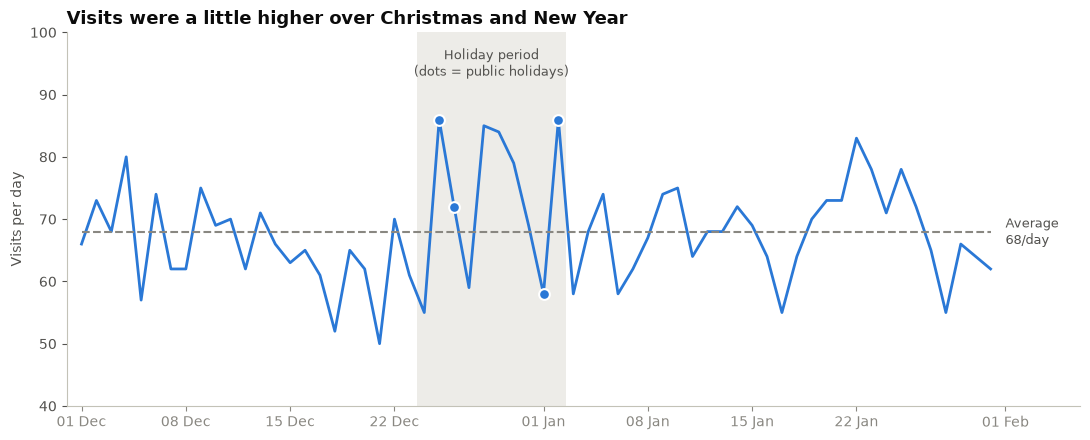

In [53]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(holiday_start - pd.Timedelta(hours=12), holiday_end + pd.Timedelta(hours=12),
           color="#e1e0d9", alpha=0.6, linewidth=0)
ax.text(holiday_start + (holiday_end - holiday_start) / 2, 95, "Holiday period\n(dots = public holidays)",
        ha="center", va="center", color="#52514e", fontsize=9)

ax.plot(daily.index, daily.values, color=BLUE, linewidth=2)
hol = daily[daily.index.isin(public_holidays)]
ax.scatter(hol.index, hol.values, color=BLUE, s=60, edgecolor="white", linewidth=1.5, zorder=3)

ax.hlines(daily.mean(), daily.index[0], daily.index[-1], color=GRAY, linestyle="--", linewidth=1.5)
ax.text(daily.index[-1] + pd.Timedelta(days=1), daily.mean(), f"Average\n{daily.mean():.0f}/day",
        va="center", color="#52514e", fontsize=9)

ax.set_ylim(40, 100)
ax.set_xlim(daily.index[0] - pd.Timedelta(days=1), daily.index[-1] + pd.Timedelta(days=6))
ax.set_title("Visits were a little higher over Christmas and New Year")
ax.set_ylabel("Visits per day")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
plt.tight_layout()
plt.show()

### 6.4 Visits by day of the week
We use the **average visits per day**, not the total. The two months contain 9 of most weekdays but only 8 Sundays, so totals would make Sunday look quieter than it really is.

In [54]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

by_weekday = (daily.groupby(daily.index.day_name())
                   .agg(days="size", total_visits="sum", avg_per_day="mean")
                   .reindex(weekday_order)
                   .round(1))
by_weekday

,days,total_visits,avg_per_day
Monday,9,629,69.9
Tuesday,9,617,68.6
Wednesday,9,584,64.9
Thursday,9,631,70.1
Friday,9,622,69.1
Saturday,9,587,65.2
Sunday,8,537,67.1


### 6.5 Chart: average visits by day of the week

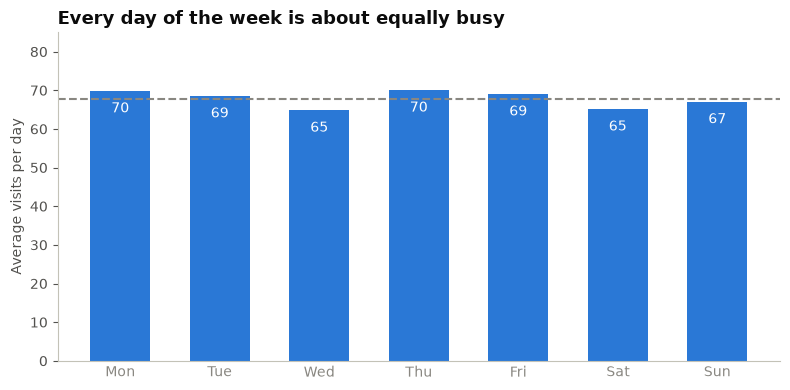

In [55]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar([d[:3] for d in by_weekday.index], by_weekday["avg_per_day"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}" for v in by_weekday["avg_per_day"]], padding=-18, color="white")
ax.axhline(daily.mean(), color=GRAY, linestyle="--", linewidth=1.5)
ax.set_ylim(0, 85)
ax.set_title("Every day of the week is about equally busy")
ax.set_ylabel("Average visits per day")
ax.tick_params(axis="x", length=0)
plt.tight_layout()
plt.show()

### 6.6 Holiday period vs the rest
We compare average visits per day across three periods: before, during and after the holidays. We also show the four public holidays on their own.

In [56]:
period_order = ["Before holidays (1–23 Dec)", "Holiday period (24 Dec – 2 Jan)", "After holidays (3–31 Jan)"]

by_period = (daily_df.groupby("period")["visits"]
                     .agg(days="size", total_visits="sum", avg_per_day="mean")
                     .reindex(period_order))
by_period.loc["Public holidays only"] = [
    daily_df["public_holiday"].sum(),
    daily_df.loc[daily_df["public_holiday"], "visits"].sum(),
    daily_df.loc[daily_df["public_holiday"], "visits"].mean(),
]
by_period.round(1)

,days,total_visits,avg_per_day
period,,,
Before holidays (1–23 Dec),23.0,1504.0,65.4
Holiday period (24 Dec – 2 Jan),10.0,733.0,73.3
After holidays (3–31 Jan),29.0,1970.0,67.9
Public holidays only,4.0,302.0,75.5


### 6.7 Is the holiday rise real?
Daily visits bounce around by chance, from about 50 to 86. To check whether the holiday rise is more than normal ups and downs, we measure the gap between the holiday period and all other days and give it a 95% range, as in Step 5. If the range stays above zero, the rise is very likely real.

In [57]:
in_hol = daily_df.loc[daily_df["period"] == period_order[1], "visits"]
rest = daily_df.loc[daily_df["period"] != period_order[1], "visits"]

gap = in_hol.mean() - rest.mean()
margin = 1.96 * (in_hol.var() / len(in_hol) + rest.var() / len(rest)) ** 0.5
verdict = "likely real" if gap - margin > 0 else "could be chance"

print(f"Holiday period: {in_hol.mean():.1f}/day vs other days: {rest.mean():.1f}/day")
print(f"Gap: {gap:+.1f} visits a day ({gap / rest.mean() * 100:+.0f}%), "
      f"95% range {gap - margin:+.1f} to {gap + margin:+.1f} → {verdict}")

Holiday period: 73.3/day vs other days: 66.8/day
Gap: +6.5 visits a day (+10%), 95% range -1.5 to +14.5 → could be chance


### 6.8 Findings: timing
- **The clinic is open and busy every day.** All 62 days had visits, averaging **68 a day** and ranging from 50 (Sun 21 Dec) to 86 (Christmas Day and Fri 2 Jan).
- **There's no clear busiest day of the week.** Thursday (70) and Monday (70) are slightly busier, and Wednesday (65) and Saturday (65) slightly quieter, but a gap of about 5 visits a day is within normal day-to-day ups and downs. Weekends are as busy as weekdays.
- **The holidays didn't make the clinic quieter.** The holiday period (24 Dec – 2 Jan) averaged **73 visits a day**, about 10% more than other days (67), and the four public holidays averaged 76. The busiest stretch was **28–30 Dec** (85, 84 and 79 visits).
- **That holiday rise isn't certain.** Its 95% range runs from −1.5 to +14.5 visits a day, so it could be normal variation. With only one holiday season in the data, we can't confirm a pattern.

**What this suggests:** staff every day of the week at a similar level, with weekends included. **Don't reduce staffing over Christmas and New Year.** Demand held up and may rise, especially in the days between Christmas and New Year. A second year of data would confirm whether the holiday rise repeats.


## Step 7: Question 6 – Referrals
**Where do referred patients come from, and which departments do they go to?**

As set out in the scope, a blank "Referred by" counts as a **walk-in**. Every other value is the town that referred the patient.

### 7.1 Referred vs walk-in

In [58]:
ref_mix = df["referred"].map({True: "Referred", False: "Walk-in"}).value_counts().to_frame("patients")
ref_mix["share_%"] = (ref_mix["patients"] / len(df) * 100).round(1)
ref_mix

,patients,share_%
referred,,
Walk-in,3592,85.4
Referred,615,14.6


### 7.2 Where referrals come from
We count referred patients by the town that referred them.

In [59]:
referred = df[df["referred"]]

by_town = referred["referred_by"].value_counts().to_frame("patients")
by_town["share_of_referrals_%"] = (by_town["patients"] / len(referred) * 100).round(1)
by_town

,patients,share_of_referrals_%
referred_by,,
Hamilton,68,11.1
Masterton,63,10.2
Napier,61,9.9
Wellington,59,9.6
Taupo,56,9.1
Gisborne,53,8.6
New Plymouth,53,8.6
Nelson,52,8.5
Tauranga,51,8.3


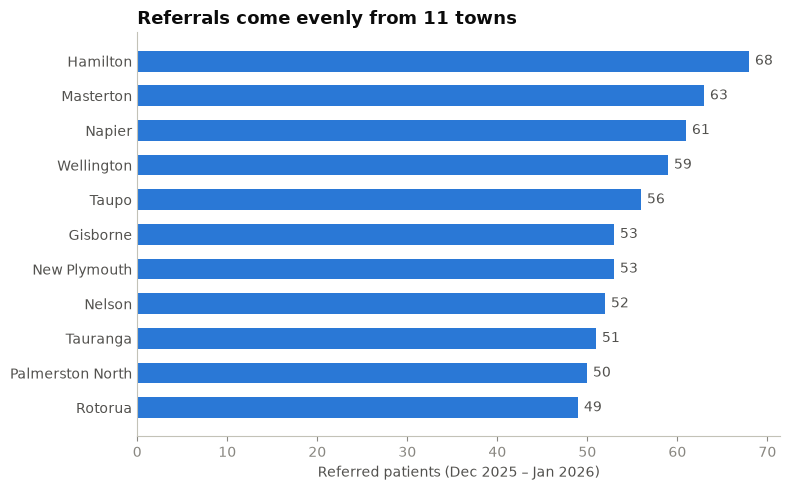

In [60]:
data = by_town.sort_values("patients")

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(data.index, data["patients"], color=BLUE, height=0.6)
ax.bar_label(bars, padding=4, color="#52514e")
ax.set_title("Referrals come evenly from 11 towns")
ax.set_xlabel("Referred patients (Dec 2025 – Jan 2026)")
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### 7.3 Which departments receive referrals
For each department, `referred` is the number of its patients who were referred and `referred_%` is their share of the department's patients. The dashed line on the chart is the clinic-wide share.

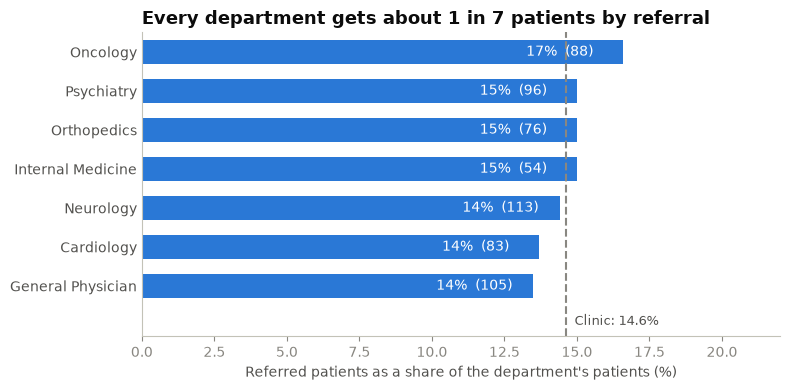

,patients,referred,referred_%
department,,,
General Physician,780,105,13.5
Cardiology,605,83,13.7
Neurology,784,113,14.4
Internal Medicine,360,54,15.0
Orthopedics,508,76,15.0
Psychiatry,640,96,15.0
Oncology,530,88,16.6


In [61]:
ref_dept = df.groupby("department").agg(patients=("patient_id", "size"), referred=("referred", "sum"))
ref_dept["referred_%"] = (ref_dept["referred"] / ref_dept["patients"] * 100).round(1)
ref_dept = ref_dept.sort_values("referred_%")
clinic_ref = df["referred"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(ref_dept.index, ref_dept["referred_%"], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%  ({n})" for v, n in zip(ref_dept["referred_%"], ref_dept["referred"])],
             padding=-70, color="white")
ax.axvline(clinic_ref, color=GRAY, linestyle="--", linewidth=1.5)
ax.text(clinic_ref + 0.3, -0.9, f"Clinic: {clinic_ref:.1f}%", color="#52514e", va="center", fontsize=9)
ax.set_ylim(-1.3, len(ref_dept) - 0.5)
ax.set_xlim(0, 22)
ax.set_title("Every department gets about 1 in 7 patients by referral")
ax.set_xlabel("Referred patients as a share of the department's patients (%)")
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

ref_dept

### 7.4 Which town sends patients to which department
Each cell is the number of patients a town referred to a department. Darker means more.

**Read with care:** most cells hold fewer than 15 patients, so a difference of a few patients between cells is likely chance.

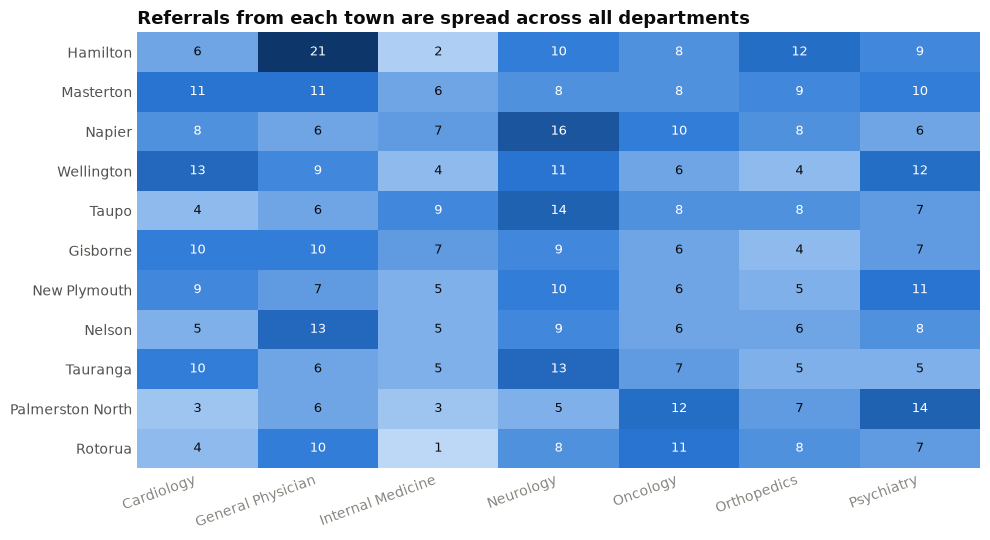

In [62]:
town_dept = pd.crosstab(referred["referred_by"], referred["department"])
town_dept = town_dept.loc[by_town.index]                    # busiest town at the top

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.imshow(town_dept, cmap=blues, aspect="auto", vmin=0, vmax=town_dept.values.max())
for i in range(town_dept.shape[0]):
    for j in range(town_dept.shape[1]):
        val = town_dept.iat[i, j]
        ax.text(j, i, val, ha="center", va="center", color="white" if val >= 8 else INK, fontsize=9)

ax.set_xticks(range(town_dept.shape[1]), town_dept.columns, rotation=20, ha="right")
ax.set_yticks(range(town_dept.shape[0]), town_dept.index)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Referrals from each town are spread across all departments")
plt.tight_layout()
plt.show()

### 7.5 Are referred patients different from walk-ins?
We compare age, length of stay and follow-up rate, then test the follow-up gap with the `compare` helper from Step 5.

In [63]:
ref_vs_walk = df.groupby(df["referred"].map({True: "Referred", False: "Walk-in"})).agg(
    patients=("patient_id", "size"),
    avg_age=("age", "mean"),
    avg_nights=("length_of_stay", "mean"),
    follow_up_pct=("follow_up_required", lambda s: s.mean() * 100),
).round(2).rename(columns={"follow_up_pct": "follow_up_%"})
display(ref_vs_walk)

fu = df["follow_up_required"]
compare("Referred vs walk-in follow-up", fu[df["referred"]], fu[~df["referred"]])

,patients,avg_age,avg_nights,follow_up_%
referred,,,,
Referred,615,46.17,0.38,23.58
Walk-in,3592,46.05,0.38,25.92


Referred vs walk-in follow-up: 23.6% vs 25.9%  →  gap -2.3 points (95% range -6.0 to +1.3) → could be chance


### 7.6 Findings: referrals
- **Most patients walk in.** Only **615 visits (14.6%)** were referred, about 1 in 7.
- **Referrals come evenly from 11 towns.** Each sent 49–68 patients. Hamilton (68), Masterton (63) and Napier (61) sent the most, but no town dominates: the biggest sends only 11% of referrals.
- **Every department gets a similar share of referred patients,** from 13.5% (General Physician) to 16.6% (Oncology). Neurology (113) and General Physician (105) receive the most referred patients in number, because they're the biggest departments.
- **There's no clear link between town and department.** Each town's referrals are spread across all seven departments, and with so few patients per cell, the differences are likely chance.
- **Referred patients are like walk-ins.** They have the same average age (46), the same length of stay, and a similar follow-up rate (24% vs 26%, a gap that could be chance).

**What this suggests:** referrals are a small, steady stream from a wide area, not tied to any department or town. As 85% of patients walk in, the clinic's demand depends mostly on walk-ins. If management wants more referrals, it could build links with the referring towns' GPs, since no town sends more than about 1 patient a day. (As the data is simulated, the even spread across towns is likely how it was generated.)

## Step 8: Summary and recommendations

Steps 2–7 answered the six key questions one at a time. This step pulls them together into **one story about how the clinic works**, and turns it into **five recommendations for management**.

Each recommendation follows the same layout:

| Part | What it tells you |
|---|---|
| **What we found** | The evidence from this analysis |
| **Scenario** | A realistic moment at the clinic that shows the problem |
| **When this applies, and when it doesn't** | The conditions under which the advice holds, so it isn't applied blindly |
| **What to do** | Concrete actions |
| **How we'll know it worked** | A measure to track |

> As the data is simulated and covers only two months, treat these as recommendations to **test**, not settled facts. Section 8.11 lists what to check first.

### 8.1 A typical day at Awesome Clinic
To make the numbers concrete, we turn two months of totals into a **typical day** by dividing each total by the 62 days covered.

In [64]:
DAYS = len(all_days)

typical_day = pd.Series({
    "Patients arriving": len(df),
    "…who walk in": (~df["referred"]).sum(),
    "…who were referred by another town": df["referred"].sum(),
    "…aged 45 or older": (df["age"] >= 45).sum(),
    "…seen in Neurology": (df["department"] == "Neurology").sum(),
    "…seen in General Physician": (df["department"] == "General Physician").sum(),
    "…who go home the same day": (df["length_of_stay"] == 0).sum(),
    "…who stay at least one night": (df["length_of_stay"] > 0).sum(),
    "…who will need a follow-up": df["follow_up_required"].sum(),
}) / DAYS

typical_day.round(0).astype(int).to_frame("per day")

,per day
Patients arriving,68
…who walk in,58
…who were referred by another town,10
…aged 45 or older,40
…seen in Neurology,13
…seen in General Physician,13
…who go home the same day,46
…who stay at least one night,22
…who will need a follow-up,17


**The story of a typical day**

The doors open and, over the day, about **68 patients** arrive. **58 of them simply walk in**. Only about **10 were sent by another town's doctors**, from places like Hamilton, Masterton or Napier. **Around 40 are 45 or older.**

About **13 head to Neurology** and **13 to General Physician**, the two busiest departments. But inside Neurology, the work isn't shared. Over the two months, one neurologist (Dr Dwight D. Eisenlower) saw **231 patients**, close to 4 a day, while a colleague in the same department (Dr Kapil Day) saw **23**, about one every three days.

By evening, **46 patients have gone home**. The other **22 stay at least one night**, and that's true in every department: about one patient in three stays overnight. Before leaving, **17 patients are told they need a follow-up**, again about the same in every department.

Then the holidays come. On **Christmas Day, 86 patients** arrive, among the busiest days of the two months. Over 28–30 December, **85, 84 and 79** arrive. The night of **29 December** has **45 occupied beds**, about 75% more than a normal night.

That's the clinic in this data: **steady and predictable** in most ways, **uneven in how doctors share the work**, and **under the most pressure exactly when staff most want time off.**

### 8.2 Key findings at a glance

| # | Question | Answer in one line | Why it matters |
|---|---|---|---|
| 1 | **Workload** | Neurology and General Physician are busiest (≈780 visits each). Doctors range from **23 to 234 visits**, a 10× gap **inside every department** | Some doctors are overloaded while others have spare time |
| 2 | **Patient profile** | Median age 48. **59% are 45+**, 55% male, and the mix is the same in every department | Plan the patient experience clinic-wide, not per department |
| 3 | **Length of stay** | **68% go home the same day**, ~1 in 3 stays overnight, similar everywhere | Bed needs follow patient volume, not department |
| 4 | **Follow-ups** | **~1 in 4 visits** needs one, with no department clearly different | Follow-up demand is predictable: about 1 slot for every 4 visits |
| 5 | **Timing** | No busiest weekday, weekends as busy as weekdays, **busiest around Christmas–New Year** | Staffing should be flat across the week and **not cut over the holidays** |
| 6 | **Referrals** | Only **15% referred**, spread evenly over 11 towns, and referred patients are like walk-ins | Demand depends on walk-ins, and referrals are a small growth opportunity |

### 8.3 One more check: how many beds are occupied each night?
Step 4 measured how long each patient stayed. For bed planning, what matters is how many patients are **in a bed on a given night**. A patient occupies a bed on every night from their in date up to, but not including, their out date.

> Patients admitted before 1 Dec aren't in the data, so the first night or two may be slightly under-counted.

In [65]:
occupied = pd.DataFrame({
    night: ((df["in_date"] <= night) & (df["out_date"] > night)).groupby(df["department"]).sum()
    for night in all_days
}).T
occupied["Clinic"] = occupied.sum(axis=1)

print(f"Average occupied beds per night: {occupied['Clinic'].mean():.1f}")
print(f"Busiest night: {occupied['Clinic'].max()} beds on {occupied['Clinic'].idxmax():%a %d %b %Y}")
occupied["Clinic"].sort_values(ascending=False).head(5).to_frame("beds occupied")

Average occupied beds per night: 25.6
Busiest night: 45 beds on Mon 29 Dec 2025


,beds occupied
2025-12-29,45
2026-01-02,37
2025-12-30,36
2025-12-31,34
2025-12-28,33


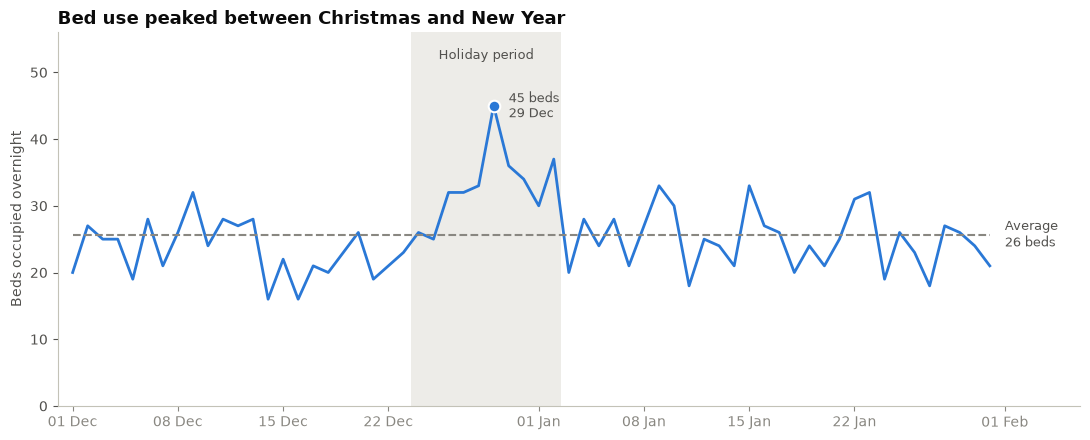

In [66]:
beds = occupied["Clinic"]
peak_night = beds.idxmax()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(holiday_start - pd.Timedelta(hours=12), holiday_end + pd.Timedelta(hours=12),
           color="#e1e0d9", alpha=0.6, linewidth=0)
ax.text(holiday_start + (holiday_end - holiday_start) / 2, 52, "Holiday period",
        ha="center", color="#52514e", fontsize=9)

ax.plot(beds.index, beds.values, color=BLUE, linewidth=2)
ax.scatter([peak_night], [beds.max()], color=BLUE, s=70, edgecolor="white", linewidth=1.5, zorder=3)
ax.text(peak_night + pd.Timedelta(days=1), beds.max(), f"{beds.max()} beds\n{peak_night:%d %b}",
        va="center", color="#52514e", fontsize=9)

ax.hlines(beds.mean(), beds.index[0], beds.index[-1], color=GRAY, linestyle="--", linewidth=1.5)
ax.text(beds.index[-1] + pd.Timedelta(days=1), beds.mean(), f"Average\n{beds.mean():.0f} beds",
        va="center", color="#52514e", fontsize=9)

ax.set_ylim(0, 56)
ax.set_xlim(beds.index[0] - pd.Timedelta(days=1), beds.index[-1] + pd.Timedelta(days=6))
ax.set_title("Bed use peaked between Christmas and New Year")
ax.set_ylabel("Beds occupied overnight")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
plt.tight_layout()
plt.show()

**What the chart shows:** on a typical night about **26 beds** are in use. Between Christmas and New Year that rose sharply, peaking at **45 on 29 December**. Step 6 couldn't say for sure that *arrivals* rose over the holidays. The bed count shows the pressure more clearly, because several busy days in a row (28–30 Dec) stacked overnight stays on top of each other.

### 8.4 Planning table: what each department needs on a typical day
This table puts Steps 2–5 into units managers plan in: patients, beds and follow-up slots **per day**. "Peak" shows the busiest day or night in the two months.

> The departments' peaks happened on different nights, so the clinic's peak (bottom row) is lower than the sum of the department peaks.

In [67]:
per_day = (df.groupby(["in_date", "department"]).size()
              .unstack(fill_value=0)
              .reindex(all_days, fill_value=0))
dept_beds = occupied.drop(columns="Clinic")

plan = pd.DataFrame({
    "patients_per_day": per_day.mean(),
    "patients_peak_day": per_day.max(),
    "overnight_stays_per_day": df[df["length_of_stay"] > 0].groupby("department").size() / DAYS,
    "beds_avg_night": dept_beds.mean(),
    "beds_peak_night": dept_beds.max(),
    "follow_ups_per_day": df.groupby("department")["follow_up_required"].sum() / DAYS,
})
plan = plan.sort_values("patients_per_day", ascending=False)
plan.loc["Clinic"] = [
    daily.mean(), daily.max(),
    (df["length_of_stay"] > 0).sum() / DAYS,
    occupied["Clinic"].mean(), occupied["Clinic"].max(),
    df["follow_up_required"].sum() / DAYS,
]
plan.round(1)

,patients_per_day,patients_peak_day,overnight_stays_per_day,beds_avg_night,beds_peak_night,follow_ups_per_day
department,,,,,,
Neurology,12.6,23.0,3.9,4.6,12.0,3.5
General Physician,12.6,23.0,4.1,4.8,10.0,3.2
Psychiatry,10.3,18.0,3.4,4.1,12.0,2.5
Cardiology,9.8,17.0,3.2,3.7,10.0,2.4
Oncology,8.5,19.0,2.8,3.2,9.0,2.4
Orthopedics,8.2,16.0,2.4,2.8,6.0,1.9
Internal Medicine,5.8,13.0,1.9,2.4,6.0,1.4
Clinic,67.9,86.0,21.7,25.6,45.0,17.4


### 8.5 Recommendation 1: Share the workload more evenly within each department

**What we found**
- Visits per doctor range from **23 to 234**, a **10× gap**. **9 doctors** see more than 1.5× the average and **10** see less than half of it.
- The gap is **inside** departments, not just between them. In Neurology one doctor saw 231 patients and another saw 23.
- It isn't caused by patient type: every department sees the same age, gender and stay pattern (Steps 3–5).

**Scenario**
> It's Monday morning in Neurology. Six patients are waiting, and four of them are lined up for Dr Eisenlower, who has averaged nearly 4 patients a day for two months. Down the corridor, Dr Kapil Day, in the same department, has seen 23 patients in 62 days. The patients wait longer than they need to. The busiest doctor is heading for burnout. The quiet doctor's time, which the clinic is paying for, goes unused.

**When this applies, and when it doesn't**
- ✅ **Applies when** the low-volume doctors are **full-time** (or have similar rostered hours) and can treat the same kinds of patients as their busy colleagues.
- ❌ **Doesn't apply when** a doctor is **part-time**, has a **narrow sub-specialty**, or has **teaching, research or management duties**. A low count is then expected, and the question becomes whether the busiest doctors need extra support instead.
- ⚠️ We **can't tell which case is true from this data**, which has no rosters or hours. That's why step 1 below comes first.

**What to do**
1. **Get the rosters.** For each doctor, record the number of sessions or hours worked over Dec–Jan and work out *visits per session*. That separates real imbalance from part-time work.
2. **Start with Neurology and General Physician.** They handle 37% of all visits and have some of the widest gaps.
3. **Use a shared department queue for walk-ins** (85% of patients). A walk-in goes to the *next available* doctor in the department rather than to a named doctor, unless continuity of care requires it.
4. **Send new referrals to doctors with spare capacity** (links to Recommendation 5).

**How we'll know it worked**
- The busiest-to-quietest ratio for **full-time** doctors falls from about 10× to **under 2×**.
- No full-time doctor sits above **1.5×** their department's average.
- Waiting times for walk-ins in Neurology and General Physician fall.

### 8.6 Recommendation 2: Plan beds and follow-ups with two simple rules of thumb

**What we found**
- **About 1 patient in 3 stays overnight** (32%), in every department and at every age.
- **About 1 visit in 4 needs a follow-up** (26%), with no department clearly different.
- Because those rates are so steady, **bed and follow-up demand follow patient volume.** The busiest departments need the most, purely because they see the most patients.

**Scenario**
> Cardiology is about to take on a new doctor, expected to add about **10 patients a week**. The manager asks: *"How many more beds and follow-up slots do we need?"* With the rules of thumb, the answer takes seconds: roughly **3 more overnight stays a week** (10 × ⅓) and **2–3 more follow-up appointments a week** (10 × ¼). There's no need to wait months to see what happens.

**When this applies, and when it doesn't**
- ✅ **Applies when** patient numbers change but the *kind* of care stays the same: a new doctor, a seasonal rise, or a new referral partner.
- ❌ **Doesn't apply when** the clinic starts a **different kind of service**, such as day surgery or a new specialty. Its stay and follow-up pattern could be very different, so measure it separately.
- ⚠️ In this simulated data every department behaves the same. In **real data**, re-check the rates for each department before relying on one clinic-wide number.

**What to do**
1. **Use the planning table (8.4)** as the starting point for each department's daily beds and follow-up slots.
2. **Plan beds for the peak, not the average.** A typical night uses about 26 beds, but the busiest used **45**. Planning for the average means running out of beds on the nights that matter most.
3. **Book follow-up slots ahead:** about **1 slot for every 4 visits**, with the most capacity in **Neurology (≈3.5 a day)** and **General Physician (≈3.2 a day)**.
4. **Book the follow-up before the patient leaves**, so the slot is planned rather than squeezed in later.

**How we'll know it worked**
- Fewer nights where occupied beds exceed what's staffed.
- Follow-up appointments available within the target time (e.g. 2 weeks) in every department.

### 8.7 Recommendation 3: Staff evenly through the week, and don't cut back over Christmas and New Year

**What we found**
- **No day of the week is clearly busier.** Daily averages range from 65 to 70, and **weekends are as busy as weekdays.**
- Arrivals **didn't fall over the holidays**. The holiday period averaged **73 a day vs 67** on other days, and Christmas Day had **86**.
- **Beds peaked at 45 on 29 December**, about 75% above a normal night, after three very busy days in a row (28–30 Dec).

**Scenario**
> It's 28 December. Half the team is on leave, and the roster was cut back on the usual assumption that "it'll be quiet over the holidays." By lunchtime the waiting room is full: 85 patients arrive that day and 84 the next. By the night of the 29th, 45 beds are occupied, nearly twice a normal night. The staff who are on duty work double, and patients wait.

**When this applies, and when it doesn't**
- ✅ **Applies now.** It's late October 2026, so the **2026–27 holiday roster is being set in the next few weeks.** That makes this the most time-sensitive recommendation.
- ✅ **Applies to weekends all year:** weekend demand matches weekdays.
- ⚠️ **One season of data:** the rise in daily *arrivals* could be chance (Step 6). The safe reading is "**don't plan for a holiday drop**" rather than "plan for a big surge." The bed peak, though, did happen this season.
- ❌ **Doesn't justify** adding permanent staff for the holidays until a second season confirms the pattern.

**What to do**
1. **Roster weekends at the same level as weekdays.**
2. **For 24 Dec – 2 Jan, roster at least normal levels.** Add **on-call cover for 27–31 Dec**, when beds filled up.
3. **Spread annual leave** across November and February rather than concentrating it over Christmas–New Year.
4. **Compare after the season:** rerun Step 6 and section 8.3 on the 2026–27 data to see whether the holiday rise repeats.

**How we'll know it worked**
- No night over the 2026–27 holidays where occupied beds exceed staffed beds.
- Waiting times over the holidays similar to the rest of the year.

### 8.8 Recommendation 4: Shape the patient experience around patients aged 45 and over

**What we found**
- **59% of patients are 45 or older.** The median is 48, and the largest group is 45–59 (38%).
- **55% of patients are men.**
- The mix is the **same in every department** (Step 3), so this is a **clinic-wide** picture, not a departmental one.

**Scenario**
> A 61-year-old walks in for a Neurology visit and stays overnight. The next morning they're told they need a follow-up in two weeks, but there's no written note, no reminder, and the follow-up desk is on another floor. Two weeks later they've forgotten the date. Multiply that by the **40 patients aged 45+** who arrive on a typical day, and missed follow-ups add up.

**When this applies, and when it doesn't**
- ✅ **Applies to clinic-wide choices:** waiting areas, signage, how appointments and follow-ups are communicated, and health information on display.
- ❌ **Doesn't call for department-specific changes.** No department has a noticeably older or younger patient mix.
- ⚠️ **Don't forget the minority:** 4% of patients are under 18 and still need suitable provision.
- ⚠️ The data has **no diagnosis or outcome information**, so it can't say which health needs to focus on. Only the patient profile is known.

**What to do**
1. **Make follow-ups easy to keep:** give a written appointment before the patient leaves, then send a text or phone reminder a few days before.
2. **Make sure waiting areas and signage** are comfortable and easy to read for older patients.
3. **Target health information** at the 45–64 age group (for example screening reminders), including messages aimed at men, who are the majority.

**How we'll know it worked**
- Higher **follow-up attendance**. This needs a new data field: whether the follow-up actually took place (see 8.11).
- Better patient feedback scores from patients aged 45+.

### 8.9 Recommendation 5: Build referral links, once capacity has been freed

**What we found**
- **85% of patients walk in.** Only **15% (≈10 a day)** are referred.
- Referrals come **evenly from 11 towns**. Even the biggest referrer, Hamilton, sends only **about one patient a day**.
- Referred patients are **just like walk-ins** in age, stay and follow-up rate, so they're no harder to care for.

**Scenario**
> A GP in Napier has a patient who needs a specialist opinion. Today that GP sends roughly one patient a day to Awesome Clinic, and the rest elsewhere or nowhere. Nobody at the clinic has ever called to say thanks or explain how to refer. Meanwhile, the clinic has doctors with spare appointments (Recommendation 1). A simple referral pathway would connect the GP's patients with those empty slots.

**When this applies, and when it doesn't**
- ✅ **Applies once Recommendation 1 has freed capacity**, or when management wants **more predictable demand**. Referred patients can be booked ahead, but walk-ins can't.
- ❌ **Doesn't apply while departments are at full stretch.** More referrals to an overloaded Neurology would only lengthen waits for its busiest doctors. **Do Recommendation 1 first.**
- ⚠️ The data doesn't show *why* patients were referred. The clinic would need to start recording that.

**What to do**
1. **Thank and report back to the top referring towns:** Hamilton, Masterton, Napier and Wellington.
2. **Create one simple referral route per department** (a named contact, phone line or email) and share it with the 11 referring towns.
3. **Assign referrals to doctors with spare capacity** first, to help balance the load.
4. **Start recording the reason for referral** so future analysis can see what the clinic is trusted for.

**How we'll know it worked**
- Referrals rise from **15%** of visits toward a target set by management (e.g. 20%).
- Referred patients are spread more evenly across doctors.

### 8.10 Where to start

The recommendations depend on each other, so the order matters:

| When | Recommendation | Why then |
|---|---|---|
| **Now (Nov 2026)** | **3: Holiday and weekend staffing** | The 2026–27 holiday roster is being set right now |
| **Now (Nov 2026)** | **1, step 1: Collect doctor rosters** | Needed before any workload changes. It's quick, and it unlocks Recommendation 1 |
| **Next 3 months** | **1: Rebalance workload** (Neurology and GP first) | Frees capacity and reduces burnout risk |
| **Next 3 months** | **2: Use the planning table** for beds and follow-ups | Easy to adopt, and it immediately improves peak planning |
| **3–6 months** | **4: Follow-up reminders and patient experience** | Needs the follow-up attendance field to measure |
| **6–12 months** | **5: Referral links** | Only once Recommendation 1 has created spare capacity |

**The thread that ties them together:** the clinic doesn't obviously need *more* doctors or beds. It needs to **use the doctors it has more evenly**, **plan for the busy nights rather than the average ones**, and **stop assuming the holidays are quiet**.

### 8.11 Limitations and what data to collect next

**Limits of this analysis**
- **The data is simulated.** Patterns like identical patient mix across departments are likely features of how it was generated. Re-run this notebook on real data before acting on department-level details.
- **Two months only** (Dec 2025 – Jan 2026), one holiday season and no other seasons.
- **No rosters or hours**, so we can't separate overloaded doctors from part-time ones (Recommendation 1).
- **No diagnosis, cost or outcome data**, so the analysis describes *usage*, not *quality of care*.
- **Dates without times**, so we can't see peak *hours* within a day.
- **The follow-up flag says a follow-up was needed**, not whether it happened.

**Data that would make the next analysis much stronger**

| Add this | So we can answer |
|---|---|
| Doctor rosters (sessions or hours) | Is the workload gap real imbalance or part-time work? |
| Arrival time (not just date) | Which hours of the day need the most staff? |
| Follow-up attended (yes/no) | Are follow-ups actually happening, and do reminders help? |
| Reason for visit or referral | What is each department really treating? |
| 12+ months of data | Is the holiday rise a real yearly pattern? |

### 8.12 Closing summary

Awesome Clinic sees about **68 patients a day**. Most walk in, most are 45 or older, two in three go home the same day, and one in four needs a follow-up. In most ways the clinic is **steady and predictable**, and that is good news, because predictable demand can be planned for.

The problems are in **how the work is shared** and **when the pressure comes**. A handful of doctors carry a large share of the patients while others in the same departments have room to spare, and the busiest nights fall between Christmas and New Year, just when staff are most likely to be away.

The fixes are practical and mostly cost little: **check the rosters, share walk-ins across each department, plan beds for the peak, keep the holiday roster at full strength, and build referral links once there's room.** Start with the holiday roster, because that decision is due now.